# EcoTriagem — Análise exploratória dos dados

Este notebook documenta a **origem, a qualidade e a preparação** dos dados usados no projeto:

1. **TrashNet** (Thung & Yang, 2016; licença MIT) — fotos de resíduos em 6 classes, usado para Visão Computacional e ML.
2. **Dataset autoral de intenções** em português — perguntas sobre descarte (treino gerado por templates + teste escrito à mão).
3. **Base de conhecimento** — regras de descarte (CONAMA 275/2001, Lei 12.305/2010) e mapa simulado de pontos de coleta em Maceió.

Execute antes: `python scripts/baixar_dados.py` e `python scripts/preparar_dados.py` (ou `bash scripts/reproduzir.sh`).

In [1]:
import sys, json
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(RAIZ))
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import config
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
df = pd.read_csv(config.ARQ_DIVISAO)
qual = json.load(open(config.DIR_METRICAS / 'qualidade_dados.json', encoding='utf-8'))
print('imagens válidas:', qual['total_imagens_validas'], '| após limpeza:', qual['total_imagens_apos_limpeza'])
print('resoluções:', qual['resolucoes'])

imagens válidas: 2527 | após limpeza: 2521
resoluções: [{'largura': 512, 'altura': 384, 'n': 2521}]


## 1. Distribuição das classes e divisão treino/validação/teste (estratificada, semente 42)

particao,treino,validacao,teste,total
classe,,,,
metal,286,61,62,409
papel,416,89,89,594
papelão,282,60,61,403
plástico,336,72,72,480
rejeito,96,21,20,137
vidro,349,74,75,498
total,1765,377,379,2521


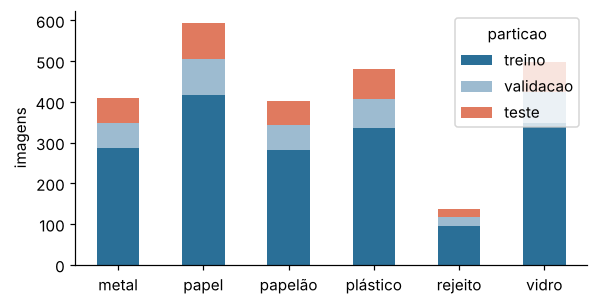

Desbalanceamento: maior/menor classe = 4.34


In [2]:
tab = pd.crosstab(df['classe'].map(config.CLASSES_PT), df['particao'])[['treino','validacao','teste']]
tab['total'] = tab.sum(axis=1); tab.loc['total'] = tab.sum()
display(tab)
ax = tab.drop('total')[['treino','validacao','teste']].plot.bar(stacked=True, figsize=(6,3), color=['#2a6f97','#9dbbd0','#e07a5f'])
ax.set_ylabel('imagens'); ax.set_xlabel(''); plt.xticks(rotation=0); plt.show()
print('Desbalanceamento: maior/menor classe =', round(tab.drop('total')['total'].max()/tab.drop('total')['total'].min(), 2))

A classe **rejeito (trash)** tem ~4× menos exemplos que **papel** — por isso todos os classificadores usam `class_weight='balanced'` e a métrica principal é o **F1-macro**, que pesa todas as classes igualmente.

## 2. Exemplos de cada classe

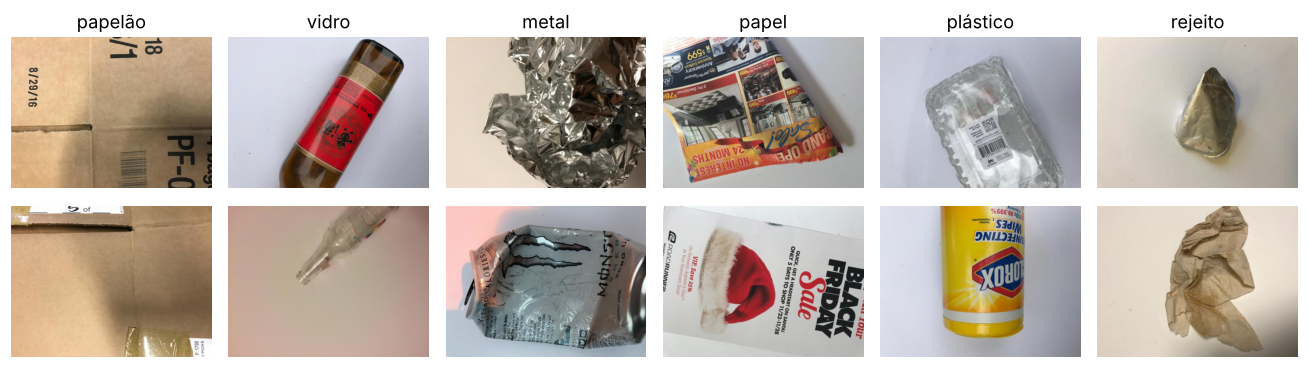

In [3]:
fig, axs = plt.subplots(2, 6, figsize=(12, 3.6))
for j, c in enumerate(config.CLASSES):
    amostra = df[df.classe == c].sample(2, random_state=1)['caminho']
    for i, p in enumerate(amostra):
        axs[i, j].imshow(cv2.cvtColor(cv2.imread(str(RAIZ / p)), cv2.COLOR_BGR2RGB)); axs[i, j].axis('off')
    axs[0, j].set_title(config.CLASSES_PT[c])
plt.tight_layout(); plt.show()

## 3. Estatísticas de imagem por classe (brilho médio)

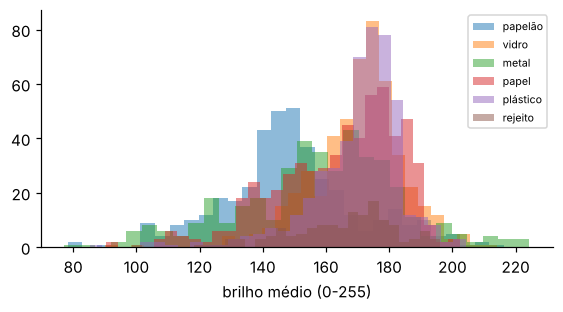

,count,mean,std,min,25%,50%,75%,max
classe,,,,,,,,
metal,409.0,157.9,25.5,77.2,142.5,160.1,174.2,224.4
papel,594.0,164.1,19.5,90.5,151.2,168.4,178.7,202.3
papelão,403.0,149.0,21.9,78.3,137.7,147.5,159.3,216.3
plástico,480.0,170.1,14.9,85.3,164.2,173.3,179.0,204.2
rejeito,137.0,164.7,17.5,98.7,154.7,168.5,176.1,196.2
vidro,498.0,170.0,14.9,90.1,162.7,172.2,178.4,214.0


In [4]:
fig, ax = plt.subplots(figsize=(6, 2.8))
for c in config.CLASSES:
    ax.hist(df[df.classe == c]['brilho_medio'], bins=30, alpha=0.5, label=config.CLASSES_PT[c])
ax.set_xlabel('brilho médio (0-255)'); ax.legend(fontsize=7); plt.show()
df.groupby(df['classe'].map(config.CLASSES_PT))['brilho_medio'].describe().round(1)

Todas as fotos têm fundo claro e iluminação semelhante — isso facilita o aprendizado, mas é uma **limitação**: fotos reais (fundo variado, vários objetos) tendem a ter desempenho menor.

## 4. Limpeza: duplicatas e rótulos conflitantes

Detecção em dois estágios: *difference hash* 16×16 (filtro) + diferença média de pixels < 5 (confirmação). Duplicatas da mesma classe são mantidas juntas na mesma partição; duplicatas com **rótulos diferentes** são ruído de rotulagem e foram removidas.

pares quase-duplicados: 15
pares com classes diferentes: 3


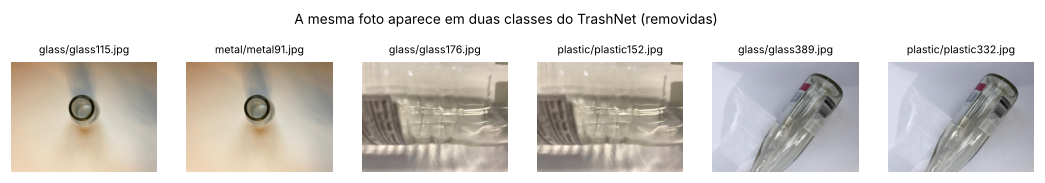

In [5]:
print('pares quase-duplicados:', qual['pares_quase_duplicados'])
print('pares com classes diferentes:', qual['pares_duplicados_com_classes_diferentes'])
fig, axs = plt.subplots(1, 6, figsize=(12, 2))
for k, (a, b) in enumerate(qual['pares_conflitantes']):
    for i, p in enumerate((a, b)):
        ax = axs[2*k + i]; ax.imshow(cv2.cvtColor(cv2.imread(str(RAIZ / p)), cv2.COLOR_BGR2RGB))
        ax.set_title(Path(p).parent.name + '/' + Path(p).name, fontsize=7); ax.axis('off')
plt.suptitle('A mesma foto aparece em duas classes do TrashNet (removidas)', fontsize=9); plt.show()

## 5. Dataset de intenções (PLN)

In [6]:
tr = pd.read_csv(config.DIR_PLN / 'intencoes_treino.csv').fillna('')
te = pd.read_csv(config.DIR_PLN / 'teste_manual.csv').fillna('')
print(f'treino (templates + aumento): {len(tr)} frases | teste manual: {len(te)} frases')
display(pd.concat([tr.intencao.value_counts().rename('treino'), te.intencao.value_counts().rename('teste manual')], axis=1))
print('comprimento médio (palavras): treino', round(tr.texto.str.split().str.len().mean(), 1), '| teste', round(te.texto.str.split().str.len().mean(), 1))
display(tr.sample(8, random_state=3))

treino (templates + aumento): 1170 frases | teste manual: 132 frases


,treino,teste manual
intencao,,
reciclavel,130,15
como_descartar,130,16
tempo_decomposicao,130,14
saudacao_ajuda,130,12
duvida_geral,130,14
identificar_material,130,16
fora_escopo,130,14
ponto_coleta,130,16
preparo_descarte,130,15


comprimento médio (palavras): treino 7.0 | teste 6.9


,texto,intencao,material,bairro
472,"estou no Cruz das Almas,, onde levo aco",ponto_coleta,metal,Cruz das Almas
376,"ei, identifica pra mim o q tem na imagem??",identificar_material,,
317,pergunta: me empresta dinheiro,fora_escopo,,
150,"ei, você consegue iedntificar o material da fo...",identificar_material,,
856,"olha, como faço descarte correto disso?",como_descartar,,
614,"me diz, lixo eletronico é lixo reciclável ou não",reciclavel,perigoso,
287,qual a distância até o ponto de coleta!,ponto_coleta,,
857,"oi, da pra recicar esse lata de sardinha??",reciclavel,metal,


In [7]:
# sobreposição exata entre treino e teste (deve ser ~0 para uma avaliação honesta)
from src.pln.preprocessamento import normalizar
inter = set(tr.texto.map(normalizar)) & set(te.texto.map(normalizar))
print('frases do teste idênticas a alguma do treino (após normalização):', len(inter), inter)

frases do teste idênticas a alguma do treino (após normalização): 0 set()


## 6. Mapa simulado de pontos de coleta (busca A*)

In [8]:
from src.decisao.busca import MapaColeta
m = MapaColeta()
print(len(m.coord), 'bairros |', sum(len(v) for v in m.adj.values())//2, 'arestas |', len(m.pontos), 'pontos de coleta (fictícios)')
pd.DataFrame([{'ponto': p['nome'], 'bairro': p['bairro'], 'aceita': ', '.join(p['aceita'])} for p in m.pontos])

32 bairros | 62 arestas | 10 pontos de coleta (fictícios)


,ponto,bairro,aceita
0,PEV Orla Ponta Verde (fictício),Ponta Verde,"papel, papelao, plastico, metal, vidro"
1,Ecoponto Jacintinho (fictício),Jacintinho,"papel, papelao, plastico, metal, vidro, oleo"
2,Ponto de logística reversa Centro (fictício),Centro,perigoso
3,Cooperativa de catadores Benedito Bentes (fict...,Benedito Bentes,"papel, papelao, plastico, metal"
4,Contêiner de vidro Jatiúca (fictício),Jatiúca,vidro
5,Coleta de óleo Farol (fictício),Farol,oleo
6,Ecoponto Tabuleiro (fictício),Tabuleiro do Martins,"papel, papelao, plastico, metal, vidro, perigo..."
7,PEV Serraria (fictício),Serraria,"papel, papelao, plastico, metal"
8,Composteira comunitária Cruz das Almas (fictício),Cruz das Almas,organico
9,PEV Trapiche (fictício),Trapiche da Barra,"papel, papelao, plastico, metal, vidro"


## 7. Resumo dos resultados (gerados por `scripts/treinar_*.py` e `scripts/experimentos.py`)

In [9]:
vis = json.load(open(config.DIR_METRICAS / 'visao.json', encoding='utf-8'))
display(pd.DataFrame(vis['modelos']).T[['val_f1_macro','val_auroc_confianca','val_ece','teste_acuracia','teste_f1_macro']].astype(float).round(3))
print('selecionado:', vis['selecionado'], '| limiares:', {k: vis['limiares'][k] for k in ('alta','minima')})
pln = json.load(open(config.DIR_METRICAS / 'pln.json', encoding='utf-8'))
display(pd.DataFrame(pln['modelos']).T.round(3))

,val_f1_macro,val_auroc_confianca,val_ece,teste_acuracia,teste_f1_macro
Clássico + SVM-RBF,0.713,0.641,0.139,0.781,0.773
Clássico + Random Forest,0.758,0.834,0.296,0.792,0.794
CNN + k-NN,0.845,0.813,0.052,0.884,0.858
CNN + SVM-RBF (Platt),0.870,0.616,0.084,0.884,0.867
CNN + SVM-RBF (isotônica),0.852,0.818,0.049,0.889,0.858
CNN + Reg. Logística,0.841,0.840,0.035,0.868,0.854
CNN + Reg. Logística + aumento,0.825,0.845,0.054,0.879,0.866


selecionado: CNN + SVM-RBF (isotônica) | limiares: {'alta': 0.84, 'minima': 0.6}


,cv5_acuracia,cv5_f1_macro,teste_acuracia,teste_f1_macro
naive_bayes,0.974,0.973,0.727,0.721
naive_bayes+char,0.980,0.980,0.826,0.818
regressao_logistica,0.981,0.981,0.788,0.775
regressao_logistica+char,0.991,0.991,0.894,0.890
svm_linear,0.982,0.982,0.773,0.762
svm_linear+char,0.991,0.991,0.856,0.852
